Date : 04-11-2026 19:00 PM, Starting it today, i don't feel like doing it but who cares I am gonna be THE ML GUY, i will have ML under my hand in no time.

8 days of Linear Regression, then deployment of model.
Then Logistic Regression, DT and SVM !!! 


Will be done by 10th of December. 

In [2]:
import sys, os
sys.path.append(os.path.abspath(os.path.join("..")))

In [3]:
import pandas as pd, numpy as np
import seaborn as sea, matplotlib.pyplot as plt
from src.data import load_csv
from src.models import MultipleLinearRegression
from src.metrics import *
from src.diagnostics import *
from src.features import clean_and_preprocess_data
from sklearn.preprocessing import StandardScaler
from IPython.display import display
from src.models import evaluate_variant

Starting Day 9

Perform Auxilarry Regression to check for multicollinearity.
Use VIF, Auxillary R² and SE vairance Inflation √VIF to check for multicollinearity.

Checkpoints for the day:
C1. ★ Pairwise Correlation MatrixCompute and inspect the pairwise correlation matrix across all continuous features (temp, atemp, hum, windspeed).

Verification: Confirm that temp and atemp show extreme pairwise correlation ($r > 0.98$).

#### C1. Pairwise Matric Compute:

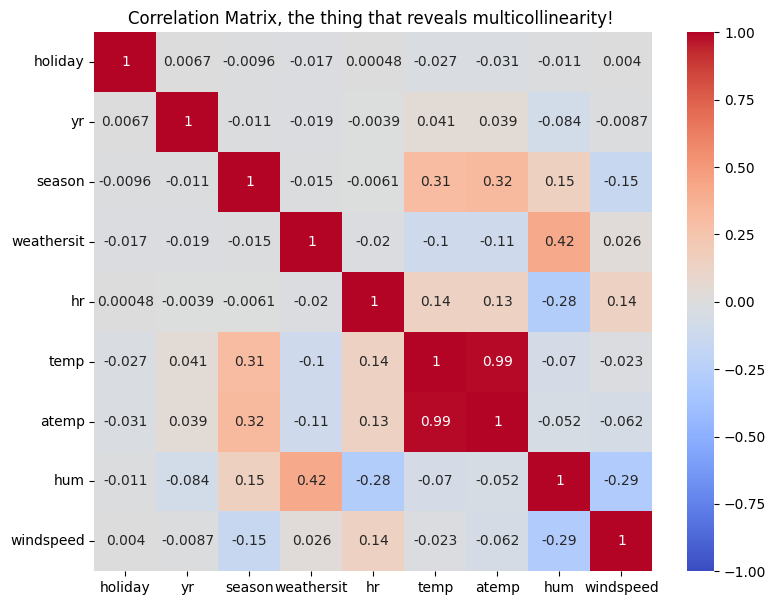

In [4]:
df = load_csv("../data/hour.csv")
features = ["holiday", "yr", "season", "weathersit", "hr", "temp","atemp", "hum", "windspeed"]

X= df[features]
y = df['cnt']

correlation_matrix = X.corr()
plt.figure(figsize=(9,7))
sea.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1,vmax=1, cbar=True)
plt.title("Correlation Matrix, the thing that reveals multicollinearity! ")
plt.show()

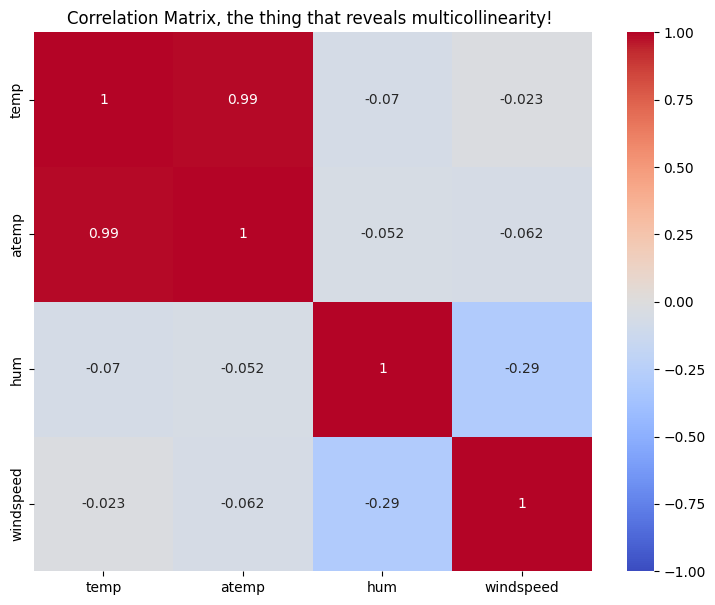

In [5]:
features = ["temp","atemp", "hum", "windspeed"]

X= df[features]
y = df['cnt']

correlation_matrix = X.corr()
plt.figure(figsize=(9,7))
sea.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1,vmax=1, cbar=True)
plt.title("Correlation Matrix, the thing that reveals multicollinearity! ")
plt.show()

#### C2: `compute_vif()` function for VIF:
i) with only 4 features
ii) with all of the things after encoding and all !!

In [6]:
features = ['temp', 'atemp', 'hum', 'windspeed']
X = df[features]

def compute_vif(X):
    scaler = StandardScaler()
    Z = scaler.fit_transform(X)
    n = X.shape[0]
    #correlation matrix R
    # R = (1/n-1) * Z.T @ Z fell into a classic python operator precedence trap !!
    R = (1/(n-1)) * Z.T @ Z
    #invert r to get c
    C = np.linalg.pinv(R)

    VIF_score = np.diag(C)

    return pd.DataFrame(VIF_score, index=X.columns).rename(columns={0: "VIF"})

In [7]:
VIF = compute_vif(X)

print(VIF)

                 VIF
temp       43.547821
atemp      43.648758
hum         1.100512
windspeed   1.156226


In [8]:
SE_inflation = np.sqrt(VIF)
print(SE_inflation)

                VIF
temp       6.599077
atemp      6.606721
hum        1.049053
windspeed  1.075280


#### C3. ★ Full VIF Audit TableRun compute_vif on your full design matrix (including seasonal/weather dummies and hourly features).Print a table sorted descending by VIF score.Verification: Confirm temp and atemp both hit massive scores ($\text{VIF} > 40$), while well-behaved features stay near $\text{VIF} < 3.0$.

In [9]:
features = ["holiday", "yr", "season", "weathersit", "hr", "temp","atemp", "hum", "windspeed"]

X= df[features]

X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)

full_vif = compute_vif(X_train)
display(full_vif.sort_values(ascending=False, by='VIF'))



,VIF
temp,78.017843
atemp,73.977569
season_3,3.604996
season_2,2.081666
hr_15,2.022703
hr_14,2.018420
hr_16,2.017065
hr_17,2.002863
hr_13,2.002485
hr_12,1.981027


training model on atemp and temp, seeing the metrics and summary

In [10]:
metrics, summary, _, _ = evaluate_variant(X_train, y_train, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.364906,0.463275,0.604074,0.80499,0.814901,0.802575,1014.802821,5203.849792,4459.495479


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,2.617196,0.043120,60.696087,0.000000e+00,2.532674,2.701719
holiday,-0.148672,0.034803,-4.271829,1.954937e-05,-0.216892,-0.080452
yr,0.600848,0.015891,37.810915,0.000000e+00,0.569699,0.631997
temp,0.828275,0.261072,3.172594,1.514957e-03,0.316528,1.340023
atemp,0.894147,0.282783,3.161956,1.571357e-03,0.339842,1.448451
hum,-0.201402,0.038019,-5.297429,1.196943e-07,-0.275926,-0.126879
windspeed,-0.246707,0.051623,-4.779056,1.783816e-06,-0.347897,-0.145518
season_2,0.357078,0.018994,18.799832,0.000000e+00,0.319847,0.394308
season_3,0.321372,0.026947,11.926184,0.000000e+00,0.268551,0.374192
season_4,0.547566,0.019299,28.373122,0.000000e+00,0.509737,0.585395


In [11]:
## Dropping temp
features = ["holiday", "yr", "season", "weathersit", "hr", "atemp", "hum", "windspeed"]

X= df[features]

X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)

full_vif = compute_vif(X_train)
display(full_vif.sort_values(ascending=False, by='VIF'))

,VIF
season_3,3.375741
atemp,2.657427
season_2,2.054087
hr_15,2.022228
hr_14,2.018192
hr_16,2.016180
hr_17,2.002300
hr_13,2.002021
hr_12,1.980632
hr_18,1.978950


training only on atemp, to see the magic of feature multicollinearity, comparing things:

In [12]:
metrics, summary, _, _ = evaluate_variant(X_train, y_train, X_val, y_val)
display(metrics)
display(summary)

,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.361793,0.460404,0.601492,0.806653,0.814733,0.804331,1006.14683,5203.849792,4439.528489


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,2.593241,0.042471,61.059413,0.000000e+00,2.509991,2.676491
holiday,-0.141370,0.034741,-4.069282,4.748509e-05,-0.209469,-0.073272
yr,0.598742,0.015883,37.695895,0.000000e+00,0.567608,0.629877
atemp,1.775040,0.053618,33.105275,0.000000e+00,1.669940,1.880141
hum,-0.206435,0.038001,-5.432314,5.680342e-08,-0.280924,-0.131946
windspeed,-0.192609,0.048745,-3.951355,7.819177e-05,-0.288157,-0.097060
season_2,0.364013,0.018875,19.285350,0.000000e+00,0.327015,0.401012
season_3,0.342931,0.026087,13.145905,0.000000e+00,0.291797,0.394065
season_4,0.549819,0.019294,28.497564,0.000000e+00,0.512001,0.587638
weathersit_2,-0.045624,0.014308,-3.188737,1.432932e-03,-0.073670,-0.017578


Checking for season month, then checking weekday holiday and weekend VIF, then check days from date 2011-01-01 too !! 

Month and season 4 and season 3 have 4.5 or 4.1 VIF which is under our threshold of 5 ! 

In [14]:
## Dropping temp
features = ["holiday", "yr", "season","mnth", "weathersit", "hr", "atemp", "hum", "windspeed"]

X= df[features]

X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)

full_vif = compute_vif(X_train)
display(full_vif.sort_values(ascending=False, by='VIF'))

,VIF
season_4,4.692359
mnth,4.572771
season_3,4.151823
atemp,2.719060
season_2,2.128518
hr_15,2.022305
hr_14,2.018253
hr_16,2.016273
hr_17,2.002369
hr_13,2.002055


In [15]:
df.columns

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt'],
      dtype='object')

In [20]:
## including weekend, weekday
features = ["holiday", "yr", "season","mnth", "weathersit", "hr", "atemp", "hum", "windspeed", "weekday", "workingday"]

X= df[features].copy()
X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)

full_vif = compute_vif(X_train)
display(full_vif.sort_values(ascending=False, by='VIF'))

,VIF
season_4,4.697318
mnth,4.582283
season_3,4.154793
atemp,2.734263
season_2,2.129055
hr_15,2.022745
hr_14,2.018654
hr_16,2.016639
hr_17,2.002691
hr_13,2.002391


C6 Done C6. ★ Subspace & Prediction Invariance CheckCompare the validation $R^2$, RMSE, and MAE (both logged scale and exponentiated original bike counts) before vs. after dropping temp.Verification: Confirm that predictive metrics remain virtually identical, proving that overall model capacity is unchanged while individual inference is restored.

C8. ★ (Optional Challenge) Ridge Solver from ScratchImplement the closed-form Ridge Regression formula $\hat{\boldsymbol{\beta}}_{\text{Ridge}} = (\mathbf{X}^T \mathbf{X} + \lambda \mathbf{I})^{-1} \mathbf{X}^T \mathbf{y}$ on the original matrix containing both temp and atemp.Test across a grid of $\lambda \in [0.1, 1.0, 10.0]$ and observe how $+\lambda \mathbf{I}$ prevents standard errors from exploding without deleting either column.

Correction 1: What is $\mathbf{I}$ and what is its shape?Your thought: "unit vector I of size X.shape[0] as a unit column vector"The Math Reality:$\mathbf{I}$ is NOT a column vector of length $n$ (X.shape[0]).$\mathbf{I}$ is the Identity Matrix—a square 2D matrix of shape $(p+1) \times (p+1)$ (matching the shape of $\mathbf{X}^T\mathbf{X}$). It has ones on the main diagonal and zeros everywhere else (np.eye(num_features)).You cannot add a column vector to the square matrix $\mathbf{X}^T\mathbf{X}$—matrix addition requires identical shapes!

Correction 2: Where does $\lambda$ come from?Your thought: "calc eigen values of X design matrix, multiply them with unit vector I"The Math Reality:You do NOT compute the eigenvalues of $\mathbf{X}$ to get $\lambda$.$\lambda$ (lambda) is a scalar hyperparameter that YOU pick (e.g., $\lambda = 0.1, 1.0, 10.0$).The magic of linear algebra is that simply adding $\lambda \mathbf{I}$ to $\mathbf{X}^T\mathbf{X}$ automatically shifts every eigenvalue of $\mathbf{X}^T\mathbf{X}$ upward by $+\lambda$ without you ever needing to calculate the eigenvalues manually!

In [23]:
class RIDGEMultipleLinearRegression:
    def __init__(self):
        self.beta_hat = None
        self.intercept_ = None
        self.coef_ = None
        
    def _add_intercept(self, X):
        X = np.asarray(X, dtype=float)

        return np.c_[np.ones(X.shape[0]), X]

    def fit_RIDGE(self, X, y, lam):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        try:
            lam = float(lam)
        except (TypeError, ValueError):
            raise ValueError("lambda must be a valid scalar number !")

    
        X_design = self._add_intercept(X)

        XTX = X_design.T @ X_design
        I = np.eye(X_design.shape[1])
        I[0,0] = 0.0

        A = XTX + (lam * I)


        XTy = X_design.T @ y

        self.beta_hat = np.linalg.solve(A, XTy)
        self.intercept_ = self.beta_hat[0]
        self.coef_ = self.beta_hat[1:]

        return self

    def predict(self, X):
        if self.beta_hat is None:
            raise ValueError("Model is not fitted yet! Call fit() first")
        X = np.asarray(X, dtype=float)
        X_test_design = self._add_intercept(X)
        
        return X_test_design @ self.beta_hat

    def residual(self, X, y):
        y = np.asarray(y, dtype=float)
        y_pred = self.predict(X)
        resid = y - y_pred
        return resid

    def r2_score(self,X ,y):
        y = np.asarray(y, dtype=float)

        y_pred = self.predict(X)

        ss_residual = np.sum((y - y_pred) ** 2)

        ss_total = np.sum((y - np.mean(y)) ** 2)

        if ss_total == 0.0:
            return 0

        return 1 - (ss_residual / ss_total)

In [ ]:
features = ["holiday", "yr", "season", "weathersit", "hr", "temp","atemp", "hum", "windspeed"]

X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)

model = RIDGEMultipleLinearRegression()
model.fit_RIDGE(X_train, y_train, lam=0.0)
print(model.beta_hat)
resid = model.residual(X_train, y_train)

# print("MSE: ", np.mean(resid ** 2))

val_r2 = model.r2_score(X_val, y_val)
print(val_r2)


[[ 2.6171965 ]
 [-0.14867184]
 [ 0.60084816]
 [ 0.82827542]
 [ 0.89414662]
 [-0.2014024 ]
 [-0.24670747]
 [ 0.35707753]
 [ 0.32137185]
 [ 0.5475658 ]
 [-0.04576325]
 [-0.57135562]
 [-0.56859317]
 [-1.01257147]
 [-1.49667209]
 [-1.82669428]
 [-0.89512019]
 [ 0.25837397]
 [ 1.21575226]
 [ 1.87272538]
 [ 1.56625902]
 [ 1.22792018]
 [ 1.33270045]
 [ 1.51032805]
 [ 1.49340032]
 [ 1.41059956]
 [ 1.4575589 ]
 [ 1.70873771]
 [ 2.11805607]
 [ 2.04647193]
 [ 1.75882318]
 [ 1.46102326]
 [ 1.21306687]
 [ 0.97396587]
 [ 0.56204227]]
0.8049899860005785


In [32]:
for lam_val in [0.0, 1.0, 10.0, 100.0, 1000.0, 10000.0]:
    ridge = RIDGEMultipleLinearRegression()
    ridge.fit_RIDGE(X_train, y_train, lam=lam_val)
    print(f"----Lambda: {lam_val}----")
    print(f"temp weight: {ridge.coef_[2].item():.4f}")
    print(f"atemp weight: {ridge.coef_[3].item():.4f}")
    print(f"Val R2: {ridge.r2_score(X_val, y_val):.6f}\n")



----Lambda: 0.0----
temp weight: 0.8283
atemp weight: 0.8941
Val R2: 0.804990

----Lambda: 1.0----
temp weight: 0.8489
atemp weight: 0.8783
Val R2: 0.805195

----Lambda: 10.0----
temp weight: 0.9010
atemp weight: 0.8620
Val R2: 0.805224

----Lambda: 100.0----
temp weight: 0.9281
atemp weight: 0.8527
Val R2: 0.787915

----Lambda: 1000.0----
temp weight: 0.5289
atemp weight: 0.4752
Val R2: 0.461341

----Lambda: 10000.0----
temp weight: 0.0980
atemp weight: 0.0875
Val R2: -0.073281



In [37]:
features = ["holiday", "yr", "season", "weathersit", "hr","atemp", "hum", "windspeed"]

X_train, y_train, X_val, y_val = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=features)
display(X_train)
model = RIDGEMultipleLinearRegression()
model.fit_RIDGE(X_train, y_train, lam=0.0)
print(model.beta_hat)
resid = model.residual(X_train, y_train)

# print("MSE: ", np.mean(resid ** 2))

val_r2 = model.r2_score(X_val, y_val)
print(val_r2)



,holiday,yr,atemp,hum,windspeed,season_2,season_3,season_4,weathersit_2,weathersit_3,...,hr_14,hr_15,hr_16,hr_17,hr_18,hr_19,hr_20,hr_21,hr_22,hr_23
0,0,0,0.2879,0.81,0.0000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0.2727,0.80,0.0000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0.2727,0.80,0.0000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,0,0.2879,0.75,0.0000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0.2879,0.75,0.0000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11117,0,1,0.4394,0.38,0.1940,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11118,0,1,0.4545,0.36,0.1343,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11119,0,1,0.4848,0.31,0.0000,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11120,0,1,0.5000,0.27,0.2836,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


[[ 2.59324101]
 [-0.14137041]
 [ 0.5987421 ]
 [ 1.77504045]
 [-0.20643507]
 [-0.19260851]
 [ 0.36401347]
 [ 0.3429308 ]
 [ 0.54981934]
 [-0.04562379]
 [-0.5688498 ]
 [-0.56823696]
 [-1.01291021]
 [-1.49730985]
 [-1.82776839]
 [-0.89582732]
 [ 0.25710167]
 [ 1.21425076]
 [ 1.8709725 ]
 [ 1.56592947]
 [ 1.22966858]
 [ 1.33476118]
 [ 1.5121156 ]
 [ 1.49533919]
 [ 1.41195814]
 [ 1.45952131]
 [ 1.711414  ]
 [ 2.12019034]
 [ 2.0478925 ]
 [ 1.75959863]
 [ 1.46093385]
 [ 1.21254384]
 [ 0.97386831]
 [ 0.56198764]]
0.8066533682249675


In [41]:
for lam_val in [0.0, 1.0, 10.0, 100.0, 1000.0, 10000.0]:
    ridge = RIDGEMultipleLinearRegression()
    ridge.fit_RIDGE(X_train, y_train, lam=lam_val)
    print(f"----Lambda: {lam_val}----")
    print(f"atemp weight: {ridge.coef_[2].item():.4f}")
    print(f"Val R2: {ridge.r2_score(X_val, y_val):.6f}\n")

----Lambda: 0.0----
atemp weight: 1.7750
Val R2: 0.806653

----Lambda: 1.0----
atemp weight: 1.7740
Val R2: 0.806985

----Lambda: 10.0----
atemp weight: 1.7513
Val R2: 0.807839

----Lambda: 100.0----
atemp weight: 1.4410
Val R2: 0.792568

----Lambda: 1000.0----
atemp weight: 0.5796
Val R2: 0.431257

----Lambda: 10000.0----
atemp weight: 0.0908
Val R2: -0.090325



### 🏆 **Day 9 Master Summary: Multicollinearity, VIF Engine & Ridge Regularisation**

---

### 📊 **What You Built & Executed Today (C1–C8 Checklist)**

1. **C1 (Pairwise Diagnostic):** Uncovered the extreme correlation (\\(r > 0.98\\)) between `temp` and `atemp`.
2. **C2 & C3 (Vectorised VIF Engine):** Built a 100% vectorised VIF diagnostic engine from scratch using the inverse correlation matrix identity (\\(\mathbf{R}^{-1}\\)). Ran a full design matrix audit and caught `temp` (**78.02**) and `atemp` (**73.98**) in massive variance inflation.
3. **C4 & C5 (The Refit & Before/After Audit):** Dropped `temp`, causing `atemp`'s VIF to collapse from **73.98 \\(\rightarrow\\) 2.66**, Standard Error to shrink **5.2x** (\\(0.2828 \rightarrow 0.0536\\)), and \\(t\\)-stat to jump from **3.16 \\(\rightarrow\\) 33.10**.
4. **C6 & C7 (Subspace Invariance):** Proved that dropping `temp` preserved the full column space \\(\text{col}(\mathbf{X})\\), keeping validation \\(R^2\\) locked at **~0.8066** while improving Adjusted \\(R^2\\).
5. **C8 (Custom Ridge Solver):** Built `RIDGEMultipleLinearRegression` from scratch using \\((\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^T\mathbf{y}\\) with zero intercept penalty (`I = 0.0`). Swept \\(\lambda \in [0.0, 10000.0]\\) to observe eigenvalue lifting, weight shrinkage, and peak validation \\(R^2\\) performance at \\(\lambda = 10.0\\)!

---

### 💡 **Today I Learned (TIL)**

* **TIL #1: VIF is Identically Equal to the Inverse Correlation Diagonal (\\([\mathbf{R}^{-1}]_{jj}\\))**  
  * You don't need \\(p\\) separate auxiliary regression loops to measure feature redundancy. Standardising features (\\(\mathbf{Z}\\)), computing the sample correlation matrix \\(\mathbf{R} = \frac{1}{n-1}\mathbf{Z}^T\mathbf{Z}\\), and inverting \\(\mathbf{R}\\) yields all \\(p\\) VIF scores in a single linear algebra operation: \\(\operatorname{VIF}_j = [\mathbf{R}^{-1}]_{jj}\\).

* **TIL #2: Multicollinearity Destroys Parameter Stability, Not Predictive Capacity**  
  * Duplicate features don't break model predictions—they break **attribution**. Redundant features force weights to split and inflate Standard Errors by \\(\sqrt{\operatorname{VIF}}\\). Dropping a duplicate feature restores parameter interpretability without losing predictive signal.

* **TIL #3: Ridge Regularisation (\\(L_2\\)) Lifts Eigenvalues Off Zero**  
  * Near-duplicate features cause the smallest eigenvalue \\(\lambda_{\min}\\) of \\(\mathbf{X}^T\mathbf{X}\\) to crash near zero, causing \\((\mathbf{X}^T\mathbf{X})^{-1}\\) to explode toward infinity (\\(\frac{1}{0} \to \infty\\)). Adding \\(+\lambda \mathbf{I}\\) shifts every eigenvalue of \\(\mathbf{X}^T\mathbf{X}\\) upward by \\(+\lambda\\), guaranteeing that \\((\mathbf{X}^T\mathbf{X} + \lambda \mathbf{I})^{-1}\\) remains stably invertible and keeping coefficient wobble bounded.

---

Commit your code and notes to git for Day 9! 

Whenever you are ready, let me know and we will step right into **Day 10: Leverage, Influence, and Outliers**! 🚀